In [24]:
import pandas as pd
from pathlib import Path
from openpyxl import load_workbook
import seaborn as sns
import matplotlib.pyplot as plt


DATA_DIR = Path("../data")
CLEANED_DATA_PATH = DATA_DIR / "interim" / "mentalhealth2to27april2025_cleaned.csv"
QUESTION_LOOKUP_PATH = DATA_DIR / "processed" / "table_questions.csv"

In [25]:
df = pd.read_csv(CLEANED_DATA_PATH)
questions_df = pd.read_csv(QUESTION_LOOKUP_PATH)

In [26]:
df = df.merge(questions_df, on="source_table", how="left")
df.insert(0, "question", df.pop("question"))

In [30]:
headline = { "Table_6": "strongly agree or agree",
            "Table_7": "strongly agree or agree"}

q1 = df[(df.breakdown_category == "Depression indicator")
        & (df.response_options.str.lower() == df.source_table.map(headline))]

In [31]:
q1

,question,source_table,breakdown_category,breakdown,response_options,estimate_(%),lcl,ucl,sample_size,weighted_count,estimate_(mean_score_out_of_10),notes,is_suppressed
293,To what extent do you agree or disagree with t...,Table_6,Depression indicator,No or mild symptoms,Strongly agree or Agree,57.0,55.0,60.0,4010,43893248,NaN,[note 4],False
300,To what extent do you agree or disagree with t...,Table_6,Depression indicator,Moderate to severe symptoms,Strongly agree or Agree,35.0,30.0,40.0,590,9946444,NaN,[note 4],False
356,To what extent do you agree or disagree with t...,Table_7,Depression indicator,No or mild symptoms,Strongly Agree or Agree,90.0,88.0,91.0,4010,43884384,NaN,[note 4],False
363,To what extent do you agree or disagree with t...,Table_7,Depression indicator,Moderate to severe symptoms,Strongly Agree or Agree,70.0,65.0,76.0,590,9946444,NaN,[note 4],False


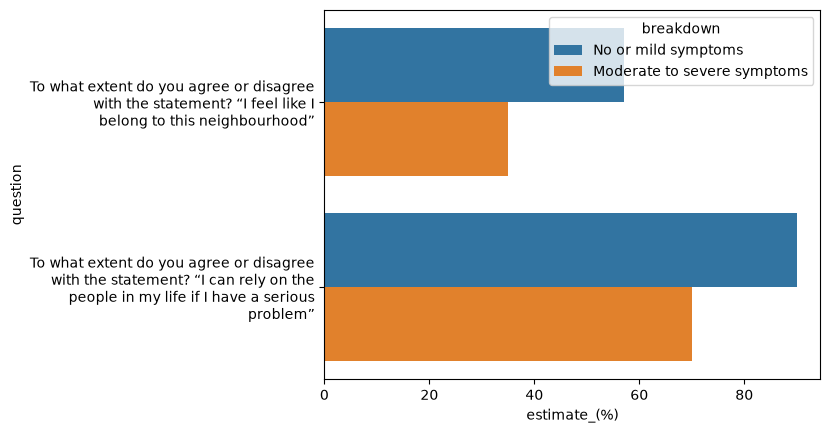

In [36]:
import textwrap

plot_df = q1.copy()
plot_df["question"] = plot_df["question"].apply(lambda s: textwrap.fill(s, width=40))

ax = sns.barplot(data=plot_df, x="estimate_(%)", y="question", hue="breakdown")